# Exploratory Data Analysis (EDA)
Analysis of hourly PM2.5 data by city.


In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import config
df = pd.read_csv(config.CLEAN_FILE, parse_dates=["datetime_pkt"])
df["month"] = df.datetime_pkt.dt.month
df["hour"] = df.datetime_pkt.dt.hour
print(df.groupby("city").pm25.describe())

def save(name):
    plt.tight_layout()
    plt.savefig(config.FIG_DIR / name, dpi=150)
    plt.show()


           count        mean        std       min        25%        50%  \
city                                                                      
karachi  11825.0   44.659645  32.463045  1.478667  25.700000  32.655556   
lahore   11892.0  103.453257  95.930381  2.165209  39.872403  59.938690   

            75%     max  
city                     
karachi   49.80  322.25  
lahore   135.47  523.00  


## 1. Time series per city

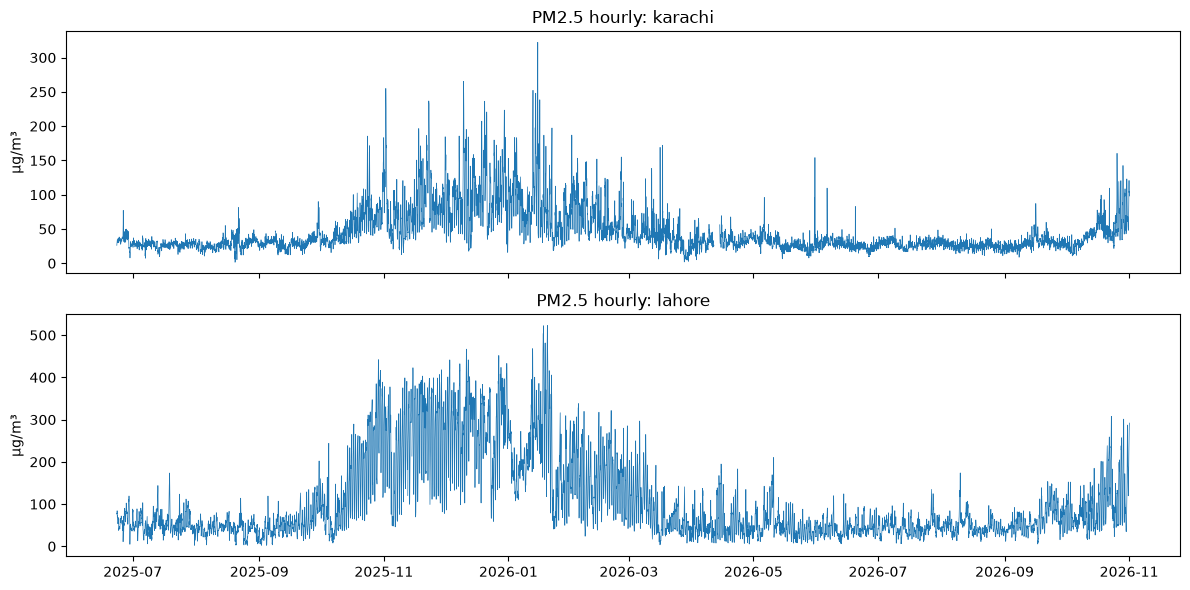

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, (city, g) in zip(axes, df.groupby("city")):
    ax.plot(g.datetime_pkt, g.pm25, lw=0.5)
    ax.set_title(f"PM2.5 hourly: {city}")
    ax.set_ylabel("µg/m³")
save("eda_timeseries.png")


## 2. Seasonality: monthly distribution

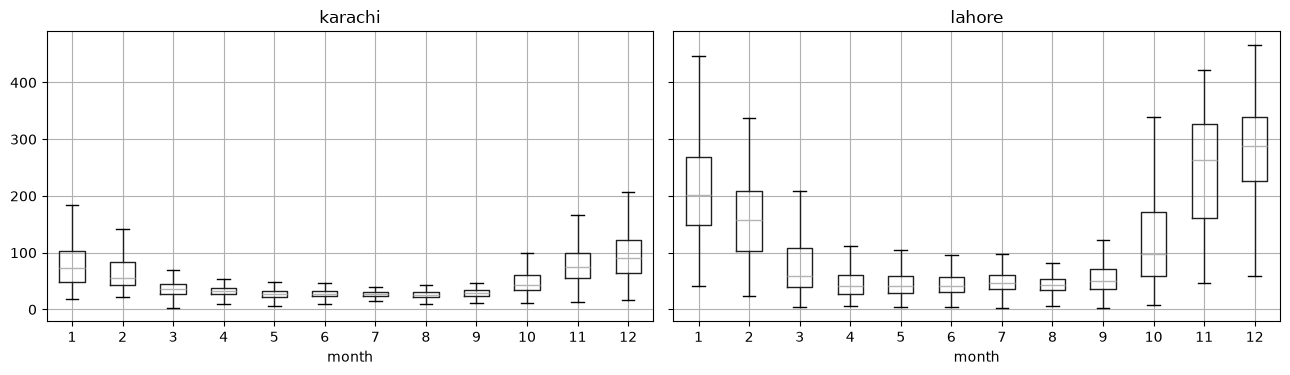

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (city, g) in zip(axes, df.groupby("city")):
    g.boxplot(column="pm25", by="month", ax=ax, showfliers=False)
    ax.set_title(city)
    ax.set_xlabel("month")
fig.suptitle("")
save("eda_monthly.png")


## 3. Daily cycle

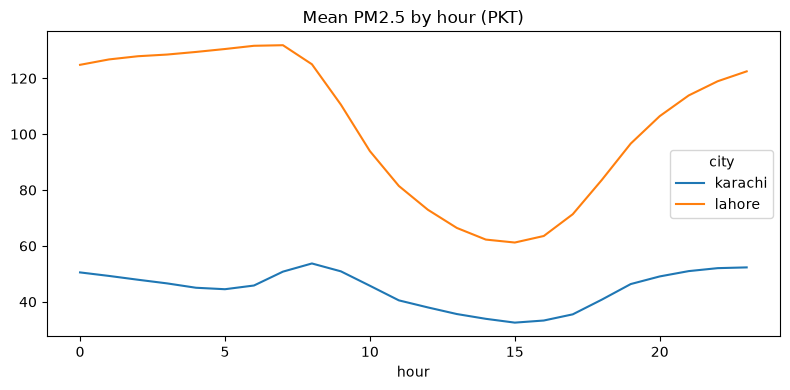

In [5]:
df.groupby(["hour", "city"]).pm25.mean().unstack().plot(
    figsize=(8, 4), title="Mean PM2.5 by hour (PKT)"
)
save("eda_hourly.png")


## 4. Missing data by month

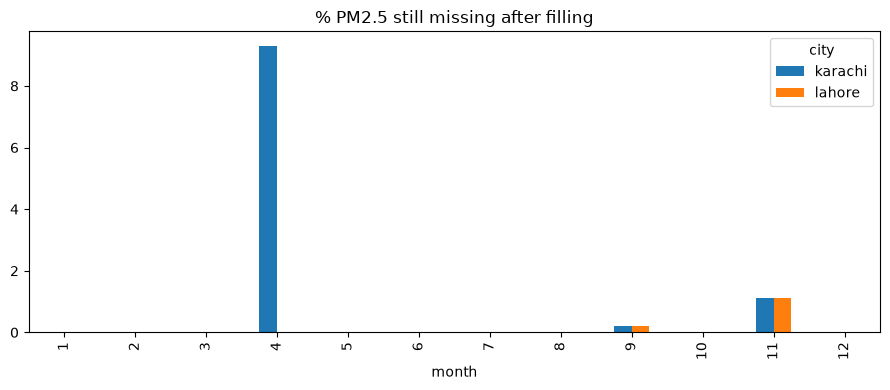

In [6]:
miss = df.assign(missing=df.pm25.isna()).groupby(["month", "city"]).missing.mean().unstack() * 100
miss.plot(kind="bar", figsize=(9, 4), title="% PM2.5 still missing after filling")
save("eda_missing.png")


## 5. PM2.5 persistence (24-hour lag correlation)

In [7]:
for city, g in df.groupby("city"):
    s = g.set_index("datetime_pkt").pm25
    print(city, "corr(pm25_t, pm25_t+24h) =", round(s.corr(s.shift(-24)), 3))


karachi corr(pm25_t, pm25_t+24h) = 0.769
lahore corr(pm25_t, pm25_t+24h) = 0.902


## 6. Weather vs. PM2.5 correlations

pm25                    1.000
temperature_2m         -0.695
relative_humidity_2m    0.127
surface_pressure       -0.082
wind_speed_10m         -0.485
precipitation          -0.059
cloud_cover            -0.114
wind_direction_10m     -0.061
Name: pm25, dtype: float64


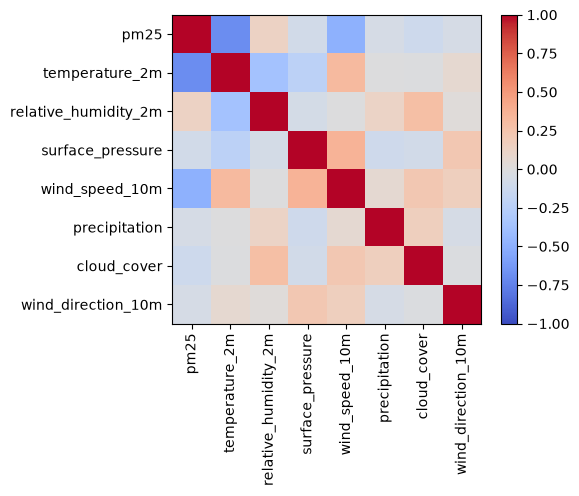

In [8]:
cols = ["pm25"] + config.WEATHER_VARS
corr = df[cols].corr()
print(corr["pm25"].round(3))
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
fig.colorbar(im)
save("eda_corr.png")


## 7. AQI-category mix

In [9]:
bins = [0, 9, 35.4, 55.4, 125.4, 225.4, 1e9]
labels = ["Good", "Moderate", "USG", "Unhealthy", "Very Unhealthy", "Hazardous"]
df["cat"] = pd.cut(df.pm25, bins=bins, labels=labels)
print(df.groupby("city").cat.value_counts(normalize=True).unstack().round(3))


cat       Good  Moderate    USG  Unhealthy  Very Unhealthy  Hazardous
city                                                                 
karachi  0.005     0.568  0.210      0.182           0.034      0.002
lahore   0.009     0.176  0.272      0.273           0.131      0.139
